# Study 2 trust and perceived accuracy
Compare the three estimate formats on two individual items. Student additional analysis; overlaps with the authors’ item-level regressions. Pairwise tests use Welch errors and Holm adjustment across all six comparisons.

In [1]:
# Import packages and locate project files.
from pathlib import Path
import os
import numpy as np
import pandas as pd
from scipy import stats
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm
from statsmodels.stats.oneway import anova_oneway
from statsmodels.stats.multitest import multipletests
from IPython.display import display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'data/raw/Study 2.xlsx').exists())
os.environ['MPLCONFIGDIR'] = str(ROOT / '.cache/matplotlib')
import matplotlib.pyplot as plt
OUT = ROOT / 'additional_robustness_checks'
for folder in ['tables', 'figures']:
    (OUT / folder).mkdir(exist_ok=True)
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':11,'axes.spines.top':False,
                     'axes.spines.right':False,'pdf.fonttype':42,'savefig.bbox':'tight'})
pd.set_option('display.max_columns', None)
pd.set_option('display.precision', 4)


In [2]:
# Apply the original Study 2 exclusions and retain both item outcomes.
d = pd.read_excel(ROOT / 'data/raw/Study 2.xlsx')
raw_n = len(d)
d = d.loc[(d.ExcludeDuplicateIP != 1) & (d.ExcludeDuplicateID != 1)].copy()
assert len(d) == 599
labels = {1:'Point', 2:'Moderate range', 3:'Wide range'}
outcomes = {'sb_trust':'Trust', 'sb_accurate':'Perceived accuracy'}
assert d.Condition.isin(labels).all()
assert d[list(outcomes)].stack().between(1,7).all()
audit = pd.DataFrame([{'study':2,'raw_n':raw_n,'retained_n':len(d),
                      'trust_missing':d.sb_trust.isna().sum(),
                      'accuracy_missing':d.sb_accurate.isna().sum()}])
audit.to_csv(OUT / 'tables/anova_sample_audit.csv', index=False)
display(audit)


,study,raw_n,retained_n,trust_missing,accuracy_missing
0,2,600,599,0,0


In [3]:
# Calculate item-specific group statistics and individual 95% t intervals.
summary = []
for item, label in outcomes.items():
    for condition, name in labels.items():
        x = d.loc[d.Condition == condition, item].dropna()
        n, mean, sd = len(x), x.mean(), x.std(ddof=1)
        margin = stats.t.ppf(.975, n-1) * sd / np.sqrt(n)
        summary.append({'outcome':label,'variable':item,'condition':name,'n':n,
                        'mean':mean,'sd':sd,'ci_low':mean-margin,'ci_high':mean+margin})
summary = pd.DataFrame(summary)
summary.to_csv(OUT / 'tables/anova_descriptives.csv', index=False)
display(summary.drop(columns='variable'))


,outcome,condition,n,mean,sd,ci_low,ci_high
0,Trust,Point,196,4.4439,1.5062,4.2317,4.6561
1,Trust,Moderate range,206,5.1214,1.3103,4.9414,5.3014
2,Trust,Wide range,197,4.6091,1.4793,4.4013,4.8170
3,Perceived accuracy,Point,196,4.4388,1.4716,4.2315,4.6461
4,Perceived accuracy,Moderate range,206,5.3107,1.1394,5.1542,5.4672
5,Perceived accuracy,Wide range,197,4.9239,1.6535,4.6915,5.1562


In [4]:
# Report classical ANOVA, Welch sensitivity, and a variance diagnostic.
anova_rows = []
for item, label in outcomes.items():
    q = d[['Condition',item]].dropna()
    model = smf.ols(f'{item} ~ C(Condition)', data=q).fit()
    table = anova_lm(model, typ=2)
    groups = [q.loc[q.Condition == condition,item].to_numpy() for condition in labels]
    F, p = stats.f_oneway(*groups)
    assert np.isclose(F, table.loc['C(Condition)','F'])
    assert np.isclose(p, table.loc['C(Condition)','PR(>F)'])
    welch = anova_oneway(groups, use_var='unequal', welch_correction=True)
    levene = stats.levene(*groups, center='median')
    anova_rows.append({'outcome':label,'n':len(q),'F':F,'df_between':len(groups)-1,
                      'df_within':model.df_resid,'p':p,
                      'welch_F':welch.statistic,'welch_df_between':welch.df_num,
                      'welch_df_within':welch.df_denom,'welch_p':welch.pvalue,
                      'levene_F':levene.statistic,'levene_p':levene.pvalue})
anova = pd.DataFrame(anova_rows)
anova['p_holm_two_outcomes'] = multipletests(anova.p,method='holm')[1]
anova['welch_p_holm_two_outcomes'] = multipletests(anova.welch_p,method='holm')[1]
anova.to_csv(OUT / 'tables/anova_tests.csv', index=False)
display(anova)


,outcome,n,F,df_between,df_within,p,welch_F,welch_df_between,welch_df_within,welch_p,levene_F,levene_p,p_holm_two_outcomes,welch_p_holm_two_outcomes
0,Trust,599,12.2961,2,596.0,5.8492e-06,13.1426,2.0,393.5477,2.9838e-06,2.0794,1.2592e-01,5.8492e-06,2.9838e-06
1,Perceived accuracy,599,18.6331,2,596.0,1.4147e-08,22.0076,2.0,382.8807,8.9706e-10,11.4578,1.3099e-05,2.8294e-08,1.7941e-09


In [5]:
# Compare all pairs with unequal-variance t tests and Holm correction over six tests.
pair_rows = []
for item, label in outcomes.items():
    for treatment, reference in [(2,1),(3,1),(3,2)]:
        x = d.loc[d.Condition == treatment,item].dropna()
        y = d.loc[d.Condition == reference,item].dropna()
        test = stats.ttest_ind(x,y,equal_var=False)
        v1, v2 = x.var(ddof=1)/len(x), y.var(ddof=1)/len(y)
        se = np.sqrt(v1+v2)
        df = (v1+v2)**2 / (v1*v1/(len(x)-1) + v2*v2/(len(y)-1))
        difference = x.mean()-y.mean()
        # Bonferroni intervals cover all six contrasts jointly at least 95%.
        margin = stats.t.ppf(1-.05/(2*6),df)*se
        pair_rows.append({'outcome':label,'contrast':labels[treatment]+' - '+labels[reference],
                          'n_treatment':len(x),'n_reference':len(y),'difference':difference,
                          'se_welch':se,'t':test.statistic,'df_welch':df,'p_raw':test.pvalue,
                          'ci_low_family95':difference-margin,'ci_high_family95':difference+margin})
pairs = pd.DataFrame(pair_rows)
pairs['p_holm_six_tests'] = multipletests(pairs.p_raw,method='holm')[1]
pairs.to_csv(OUT / 'tables/anova_posthoc.csv',index=False)
display(pairs)


,outcome,contrast,n_treatment,n_reference,difference,se_welch,t,df_welch,p_raw,ci_low_family95,ci_high_family95,p_holm_six_tests
0,Trust,Moderate range - Point,206,196,0.6775,0.1411,4.8014,386.3724,2.2563e-06,0.3033,1.0517,1.1282e-05
1,Trust,Wide range - Point,197,196,0.1653,0.1506,1.0973,390.7910,2.7319e-01,-0.2341,0.5646,2.7319e-01
2,Trust,Wide range - Moderate range,197,206,-0.5122,0.1394,-3.6735,390.3548,2.7261e-04,-0.8820,-0.1425,1.0905e-03
3,Perceived accuracy,Moderate range - Point,206,196,0.8719,0.1317,6.6194,367.2389,1.2806e-10,0.5225,1.2213,7.6834e-10
4,Perceived accuracy,Wide range - Point,197,196,0.4851,0.1579,3.0725,386.2439,2.2735e-03,0.0664,0.9038,6.8205e-03
5,Perceived accuracy,Wide range - Moderate range,197,206,-0.3868,0.1421,-2.7230,346.1676,6.7961e-03,-0.7638,-0.0099,1.3592e-02


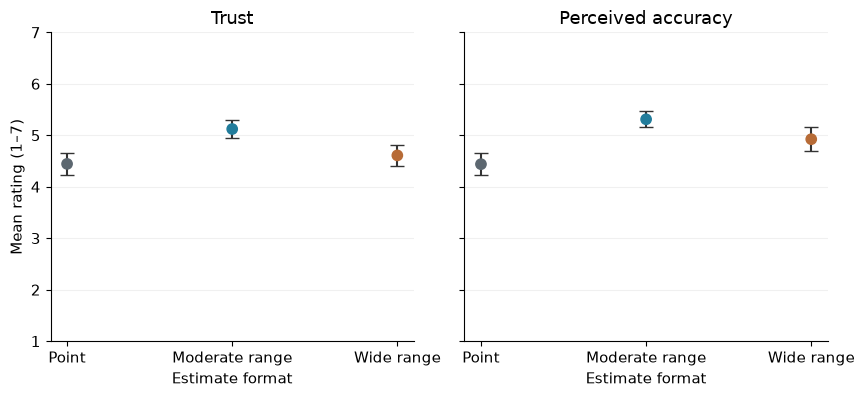

In [6]:
# Plot group means with individual 95% confidence intervals.
fig, axes = plt.subplots(1,2,figsize=(8.8,4.1),sharey=True)
colors = ['#5c6770','#217c9b','#b76b36']
for ax, outcome in zip(axes,outcomes.values()):
    q = summary.loc[summary.outcome == outcome]
    ax.errorbar(np.arange(3),q['mean'],
                yerr=[q['mean']-q.ci_low,q.ci_high-q['mean']],fmt='none',ecolor='#333333',capsize=5)
    ax.scatter(np.arange(3),q['mean'],s=55,c=colors,zorder=3)
    ax.set(xticks=np.arange(3),xticklabels=['Point','Moderate range','Wide range'],
           ylim=(1,7),title=outcome,xlabel='Estimate format')
    ax.grid(axis='y',alpha=.18)
axes[0].set_ylabel('Mean rating (1–7)')
fig.tight_layout()
for suffix in ['png','pdf']:
    fig.savefig(OUT / f'figures/study2_trust_accuracy.{suffix}',dpi=300)
plt.show()
